# 04: GFNet Model

Implement and train a Global Filter Network (GFNet) for Alzheimer's Disease (AD) and Normal Control (NC) classification using 2D MRI slices.

The model uses learnable frequency-domain filters and 2D Fast Fourier Transforms (FFT) to capture global image features.

### Step 1: Import Libraries and Set Device

In [7]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: NVIDIA A100-SXM4-40GB


# Step 2: Load Training, Validation, and Test Data

Load the patient-independent training, validation, and test splits generated in `02_preprocessing.ipynb`. Verify dataset sizes, class distributions, and patient independence before GFNet training.

In [33]:
# Set dataset folder
split_folder = "/content/drive/MyDrive/COMP3710/project/dataset/splits"

# Set CSV file paths
train_path = os.path.join(split_folder, "train.csv")
val_path = os.path.join(split_folder, "val.csv")
test_path = os.path.join(split_folder, "test.csv")

# Load training records
train_df = pd.read_csv(
    train_path,
    dtype={"image_id": str, "patient_id": str}
)

# Load validation records
val_df = pd.read_csv(
    val_path,
    dtype={"image_id": str, "patient_id": str}
)

# Load test records
test_df = pd.read_csv(
    test_path,
    dtype={"image_id": str, "patient_id": str}
)

# Display dataset sizes
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

# Display class distributions
print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTest class distribution:")
print(test_df["label"].value_counts())

# Get patient IDs
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

# Check patient overlap
train_val_overlap = train_patients & val_patients
train_test_overlap = train_patients & test_patients
val_test_overlap = val_patients & test_patients

print("\nTrain / Validation overlap:", len(train_val_overlap))
print("Train / Test overlap:", len(train_test_overlap))
print("Validation / Test overlap:", len(val_test_overlap))

# Verify patient independence
assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\nPASS: All datasets are patient-independent.")

Training images: 21620
Validation images: 4460
Test images: 4440

Training class distribution:
label
NC    11000
AD    10620
Name: count, dtype: int64

Validation class distribution:
label
AD    2240
NC    2220
Name: count, dtype: int64

Test class distribution:
label
NC    2440
AD    2000
Name: count, dtype: int64

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

PASS: All datasets are patient-independent.


In [9]:
n_train = train_df["patient_id"].nunique()
n_val = val_df["patient_id"].nunique()

print("Training patients:", n_train)
print("Validation patients:", n_val)
print(f"Validation patient ratio: {n_val / (n_train + n_val):.2%}")

Training patients: 452
Validation patients: 113
Validation patient ratio: 20.00%


In [41]:
for name, records in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    counts = records["label"].value_counts().reindex(
        ["NC", "AD"], fill_value=0
    )

    summary = pd.DataFrame({
        "Images": counts,
        "Percentage (%)": (counts / len(records) * 100).round(2)
    })

    print(f"\n{name}: {len(records)} images")
    print(summary)


Train: 21620 images
       Images  Percentage (%)
label                        
NC      11000           50.88
AD      10620           49.12

Validation: 4460 images
       Images  Percentage (%)
label                        
NC       2220           49.78
AD       2240           50.22

Test: 4440 images
       Images  Percentage (%)
label                        
NC       2440           54.95
AD       2000           45.05


# Step 3: Cache MRI Images Locally

Extract the MRI image archives from Google Drive to Colab local storage to reduce data loading latency during GFNet training. Verify that the extracted files match the training and test records.

In [34]:
import zipfile

# Set dataset paths
source_folder = "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"
cache_folder = "/content/mri_cache"

start_time = time.time()

# Extract training and test ZIP files
for split in ["train", "test"]:

    for label in ["AD", "NC"]:

        zip_path = os.path.join(
            source_folder, split, label + ".zip"
        )

        output_folder = os.path.join(
            cache_folder, split, label
        )

        os.makedirs(output_folder, exist_ok=True)

        print("Extracting:", zip_path, flush=True)

        with zipfile.ZipFile(zip_path, "r") as zip_file:
            zip_file.extractall(output_folder)

        print("Finished:", split, label, flush=True)

elapsed_time = time.time() - start_time

print("\nExtraction completed.")
print("Time:", elapsed_time, "seconds")

Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/AD.zip
Finished: train AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/NC.zip
Finished: train NC
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/AD.zip
Finished: test AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/NC.zip
Finished: test NC

Extraction completed.
Time: 4.2314019203186035 seconds


# Step 3.1: Update Image Paths

Create local image paths for the training, validation, and test datasets. Validation images are loaded from the original training image directory.

In [35]:
# Original image root and local cache root
source_folder = (
    "/content/drive/MyDrive/COMP3710/project/"
    "dataset/raw/ADNI/AD_NC"
)
cache_folder = "/content/mri_cache"

# Preserve each image's ORIGINAL folder location
def get_local_path(original_path):
    relative_path = os.path.relpath(original_path, source_folder)
    return os.path.join(cache_folder, relative_path)

for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    split_df["local_path"] = split_df["path"].apply(get_local_path)

    missing = split_df.loc[
        ~split_df["local_path"].map(os.path.isfile),
        "local_path"
    ]

    print(f"\n{name} images: {len(split_df)}")
    print("Missing cached images:", len(missing))

    if len(missing):
        print(missing.head().to_string(index=False))

    assert len(missing) == 0, f"{name}: cached images are missing."


Train images: 21620
Missing cached images: 0

Validation images: 4460
Missing cached images: 0

Test images: 4440
Missing cached images: 0


## Step 4: Create PyTorch Dataset and DataLoader

Prepare the MRI images for GFNet training. Convert grayscale images into PyTorch tensors and create datasets for the training and test sets.

# Step 4.1: Define Image Transforms

Resize MRI images to 128 × 128 pixels, convert them to tensors, and normalize pixel values to the range [-1, 1].

In [68]:
# Define image preprocessing
image_transform = transforms.Compose([

    # Resize images to 128 x 128
    transforms.Resize((256, 256)),

    # Convert images to PyTorch tensors
    transforms.ToTensor(),

    # Normalize grayscale pixel values
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )

])

# Data augmentation for training only
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.98, 1.02),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0
    ),

    transforms.ToTensor(),

    # Random erasing: apply before normalization
    transforms.RandomErasing(
        p=0.4,
        scale=(0.01, 0.10),
        ratio=(0.5, 2.0),
        value=0
    ),

    # Random elastic deformation
    transforms.RandomApply(
        [
            transforms.ElasticTransform(
                alpha=10.0,
                sigma=3.0,
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=0
            )
        ],
        p=0.3
    ),

    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])

print("Image transforms:")
print(image_transform)

Image transforms:
Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5], std=[0.5])
)


### Step 4.2: Create MRI Dataset Class

Define a custom PyTorch Dataset to load MRI images from local storage, apply image transformations, and convert AD/NC labels into numerical values.

In [69]:
# Define MRI dataset
class MRIDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        # Convert class labels to numerical values
        self.label_map = {
            "NC": 0,
            "AD": 1
        }

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        # Get one image record
        record = self.dataframe.iloc[index]

        # Get image path and label
        image_path = record["local_path"]
        label = self.label_map[record["label"]]

        # Load grayscale MRI image
        image = Image.open(image_path).convert("L")

        # Apply image transformations
        if self.transform is not None:
            image = self.transform(image)

        return image, label


print("MRI Dataset class created successfully.")

MRI Dataset class created successfully.


# Step 4.3: Create and Verify MRI Datasets

Create training, validation, and test datasets using the custom MRI Dataset class. Verify dataset sizes, image tensor shapes, and numerical class labels.

In [70]:
# Create training dataset
# train_dataset = MRIDataset(
#     dataframe=train_df,
#     transform=image_transform
# )

train_dataset = MRIDataset(
    dataframe=train_df,
    transform=train_transform
)
# Create validation dataset
val_dataset = MRIDataset(
    dataframe=val_df,
    transform=image_transform
)

# Create test dataset
test_dataset = MRIDataset(
    dataframe=test_df,
    transform=image_transform
)

# Check dataset sizes
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

# Load one training image
image, label = train_dataset[0]

# Check image and label
print("\nImage shape:", image.shape)
print("Image data type:", image.dtype)
print("Label:", label)

# Check pixel value range
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

# Load one validation image
val_image, val_label = val_dataset[0]

print("\nValidation image shape:", val_image.shape)
print("Validation label:", val_label)

# Load one test image
test_image, test_label = test_dataset[0]

print("\nTest image shape:", test_image.shape)
print("Test label:", test_label)

Training images: 21620
Validation images: 4460
Test images: 4440

Image shape: torch.Size([1, 256, 256])
Image data type: torch.float32
Label: 1
Minimum pixel value: -1.0
Maximum pixel value: 0.8196078538894653

Validation image shape: torch.Size([1, 256, 256])
Validation label: 1

Test image shape: torch.Size([1, 256, 256])
Test label: 1


# Step 4.4: Create DataLoaders

Create PyTorch DataLoaders for training, validation, and test datasets. Shuffle the training data while keeping validation and test data in a fixed order.

In [71]:
# Set batch size
batch_size = 32

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=8,
    pin_memory=True
)

# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    pin_memory=True
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    pin_memory=True
)

# Check DataLoader sizes
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Load one training batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels:", labels[:10])

Training batches: 676
Validation batches: 140
Test batches: 139

Batch image shape: torch.Size([32, 1, 256, 256])
Batch label shape: torch.Size([32])
Labels: tensor([0, 0, 0, 1, 0, 0, 1, 0, 0, 0])


In [16]:
import os

print("Available CPUs:", len(os.sched_getaffinity(0)))

Available CPUs: 12


### Step 5.1: Define Global Filter Layer

Implement a learnable global filter using the 2D Fast Fourier Transform (FFT). The layer transforms image features into the frequency domain, applies learnable complex-valued filters, and converts the filtered features back to the spatial domain.

In [17]:
# Define Global Filter layer
class GlobalFilter(nn.Module):

    def __init__(self, height, width, channels):

        super().__init__()

        # Store spatial dimensions
        self.height = height
        self.width = width
        self.channels = channels

        # Create learnable complex-valued frequency filters
        self.complex_weight = nn.Parameter(
            torch.randn(
                channels,
                height,
                width // 2 + 1,
                2
            ) * 0.02
        )

    def forward(self, x):

        # Apply 2D FFT
        x = torch.fft.rfft2(
            x,
            dim=(-2, -1),
            norm="ortho"
        )

        # Convert filter weights to complex numbers
        weight = torch.view_as_complex(
            self.complex_weight
        )

        # Apply learnable frequency filter
        x = x * weight

        # Apply inverse 2D FFT
        x = torch.fft.irfft2(
            x,
            s=(self.height, self.width),
            dim=(-2, -1),
            norm="ortho"
        )

        return x


print("Global Filter layer created successfully.")

Global Filter layer created successfully.


### Step 5.2: Define GFNet Model

Build a GFNet-inspired architecture for MRI classification. A convolutional stem extracts initial image features, followed by learnable global frequency filters and a classification head.

In [18]:
# Small GFNet adapted for 128 × 128 grayscale MRI slices.
# Architecture reference:
# https://github.com/raoyongming/GFNet/blob/master/gfnet.py

class GFBlock(nn.Module):
    def __init__(self, dim, grid_size, mlp_ratio=4, dropout=0.1):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)
        self.filter = GlobalFilter(grid_size, grid_size, dim)
        self.norm2 = nn.LayerNorm(dim)

        hidden_dim = dim * mlp_ratio
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )

    # def forward(self, x):
    #     # x: [batch, height, width, channels]
    #     residual = x
    #     x = self.norm1(x)

    #     # Existing GlobalFilter expects channels first
    #     x = x.permute(0, 3, 1, 2).contiguous()
    #     x = self.filter(x)
    #     x = x.permute(0, 2, 3, 1).contiguous()

    #     x = self.mlp(self.norm2(x))
    #     return residual + x

    def forward(self, x):
      # x: [batch, height, width, channels]

      # First residual connection: Global Filter
      residual = x

      x = self.norm1(x)

      # Convert to channels-first format
      x = x.permute(0, 3, 1, 2).contiguous()

      # Apply Global Filter
      x = self.filter(x)

      # Convert back to channels-last format
      x = x.permute(0, 2, 3, 1).contiguous()

      # First residual addition
      x = residual + x

      # Second residual connection: MLP
      x = x + self.mlp(self.norm2(x))

      return x


class GFNet(nn.Module):
    def __init__(self, image_size=128, patch_size=8,
                 dim=128, depth=4, dropout=0.1):
        super().__init__()

        assert image_size % patch_size == 0
        grid_size = image_size // patch_size

        # Convert image into a grid of patch features
        self.patch_embed = nn.Conv2d(
            1, dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(1, grid_size, grid_size, dim)
        )
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        self.pos_drop = nn.Dropout(dropout)

        self.blocks = nn.Sequential(*[
            GFBlock(dim, grid_size, dropout=dropout)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(dim)
        self.classifier = nn.Linear(dim, 2)

    def forward(self, x):
        x = self.patch_embed(x)
        x = x.permute(0, 2, 3, 1).contiguous()

        x = self.pos_drop(x + self.pos_embed)
        x = self.blocks(x)
        x = self.norm(x)

        # Average over the spatial grid
        x = x.mean(dim=(1, 2))
        return self.classifier(x)


print("Updated GFNet model class created.")

Updated GFNet model class created.


### Step 5.3: Create and Verify GFNet Model

Initialize the GFNet model on the selected device. Check the number of trainable parameters and verify the input and output tensor shapes.

In [ ]:
# Create GFNet model
model = GFNet(
    image_size=256,
    patch_size=16,
    dim=128,
    depth=12,
    dropout=0.1
).to(device)

# Display model architecture
print(model)

# Count trainable parameters
total_params = 0

for p in model.parameters():
    if p.requires_grad:
        total_params += p.numel()

print("\nTotal trainable parameters:", total_params)

# Check model device
print("Model device:", next(model.parameters()).device)

In [51]:
# Load one training batch
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Set model to evaluation mode
model.eval()

# Test forward pass without computing gradients
with torch.no_grad():
    outputs = model(images)

# Check input and output shapes
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

# Check predicted classes
predictions = torch.argmax(outputs, dim=1)

print("Predictions:", predictions[:10])
print("Actual labels:", labels[:10])

Input shape: torch.Size([32, 1, 256, 256])
Output shape: torch.Size([32, 2])
Predictions: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], device='cuda:0')
Actual labels: tensor([0, 1, 0, 0, 0, 0, 0, 0, 0, 1])


# Step 6: Train GFNet Model

Train the GFNet model using cross-entropy loss and the Adam optimizer. Record training loss and accuracy for each epoch to monitor model learning. The test set is reserved for final evaluation.



# Step 6.1: Set Training Parameters

Configure the training parameters, loss function, and optimizer for GFNet. Initialize a fresh model and prepare training and validation history to monitor model performance and detect overfitting.

In [72]:
# Set random seed for reproducibility
random_seed = 42

torch.manual_seed(random_seed)
np.random.seed(random_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

# Initialize a fresh GFNet model
model = GFNet(
    image_size=256,
    patch_size=16,
    dim=384,
    depth=12,
    dropout=0.1
).to(device)

print("GFNet model initialized successfully.")

# Set training parameters
epochs = 10
learning_rate = 0.0003

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=0.0005
)

# Gradually reduce the learning rate over 15 epochs
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
)

# Store training history
train_loss_history = []
train_acc_history = []

# Store validation history
val_loss_history = []
val_acc_history = []

# Track the best validation loss
best_val_loss = float("inf")
best_epoch = 0

# Set checkpoint path
checkpoint_path = (
    "/content/drive/MyDrive/COMP3710/project/gfnet_best.pth"
)

# Display training settings
print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Loss function:", criterion)
print("Optimizer: AdamW")

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nModel device:", next(model.parameters()).device)

GFNet model initialized successfully.
Epochs: 10
Learning rate: 0.0003
Loss function: CrossEntropyLoss()
Optimizer: AdamW

Training images: 21620
Validation images: 4460
Test images: 4440

Training batches: 676
Validation batches: 140
Test batches: 139

Model device: cuda:0


In [74]:
print("Training history length:", len(train_loss_history))
print("Validation history length:", len(val_loss_history))
print("Best validation loss:", best_val_loss)
print("Best epoch:", best_epoch)
print("Checkpoint path:", checkpoint_path)

# Verify that the optimizer references the current model
model_params = {id(p) for p in model.parameters()}
optimizer_params = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}
print("Optimizer matches model:", model_params == optimizer_params)

Training history length: 0
Validation history length: 0
Best validation loss: inf
Best epoch: 0
Checkpoint path: /content/drive/MyDrive/COMP3710/project/gfnet_best.pth
Optimizer matches model: True


# Step 6.2: Train GFNet with Validation

Train GFNet for 30 epochs and evaluate its performance on the validation dataset after each epoch. Record training and validation loss and accuracy to monitor learning progress and identify potential overfitting. The test dataset is not used during training.

In [75]:
# Continue training from the completed epochs
# start_epoch = len(train_loss_history)
# epochs = 20
# for epoch in range(start_epoch, epochs):

# # Train GFNet with validation
for epoch in range(epochs):

    # ========================================
    # 1. Training
    # ========================================

    model.train()

    train_total_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate training loss
        train_total_loss += loss.item() * images.size(0)

        # Get predicted classes
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Calculate training metrics
    train_loss = train_total_loss / train_total
    train_acc = train_correct / train_total

    # Store training history
    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)

    # ========================================
    # 2. Validation
    # ========================================

    model.eval()

    val_total_loss = 0.0
    val_correct = 0
    val_total = 0

    # Disable gradient computation
    with torch.no_grad():

        for images, labels in val_loader:

            # Move images and labels to GPU
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            # Accumulate validation loss
            val_total_loss += loss.item() * images.size(0)

            # Get predicted classes
            predictions = torch.argmax(outputs, dim=1)

            # Count correct predictions
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # Calculate validation metrics
    val_loss = val_total_loss / val_total
    val_acc = val_correct / val_total

    # Store validation history
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    # Save model when validation loss improves
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      best_epoch = epoch + 1

      torch.save(
          model.state_dict(),
          checkpoint_path
      )

      print(f"Best model saved at Epoch {best_epoch}")

    # ========================================
    # 3. Display epoch results
    # ========================================

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc * 100:.2f}%",
        flush=True
    )
    print(f"Learning rate used: {optimizer.param_groups[0]['lr']:.8f}")
    scheduler.step()

# ========================================
# 4. Display best model information
# ========================================
print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint path:", checkpoint_path)

Best model saved at Epoch 1
Epoch [1/10] Train Loss: 0.6811 Train Acc: 57.64% | Val Loss: 0.6544 Val Acc: 63.39%
Learning rate used: 0.00030000
Best model saved at Epoch 2
Epoch [2/10] Train Loss: 0.5890 Train Acc: 68.48% | Val Loss: 0.5943 Val Acc: 67.49%
Learning rate used: 0.00029268
Best model saved at Epoch 3
Epoch [3/10] Train Loss: 0.5605 Train Acc: 70.72% | Val Loss: 0.5744 Val Acc: 70.18%
Learning rate used: 0.00027145
Epoch [4/10] Train Loss: 0.5361 Train Acc: 72.55% | Val Loss: 0.6071 Val Acc: 67.91%
Learning rate used: 0.00023837
Epoch [5/10] Train Loss: 0.5096 Train Acc: 74.38% | Val Loss: 0.6207 Val Acc: 69.33%
Learning rate used: 0.00019670
Best model saved at Epoch 6
Epoch [6/10] Train Loss: 0.4859 Train Acc: 76.37% | Val Loss: 0.5729 Val Acc: 71.50%
Learning rate used: 0.00015050
Best model saved at Epoch 7
Epoch [7/10] Train Loss: 0.4628 Train Acc: 77.84% | Val Loss: 0.5716 Val Acc: 73.09%
Learning rate used: 0.00010430
Epoch [8/10] Train Loss: 0.4375 Train Acc: 79.10

# Step 6.3: Plot Training and Validation Curves

Visualize training and validation loss and accuracy across 30 epochs to evaluate model convergence, identify overfitting, and compare generalization performance.

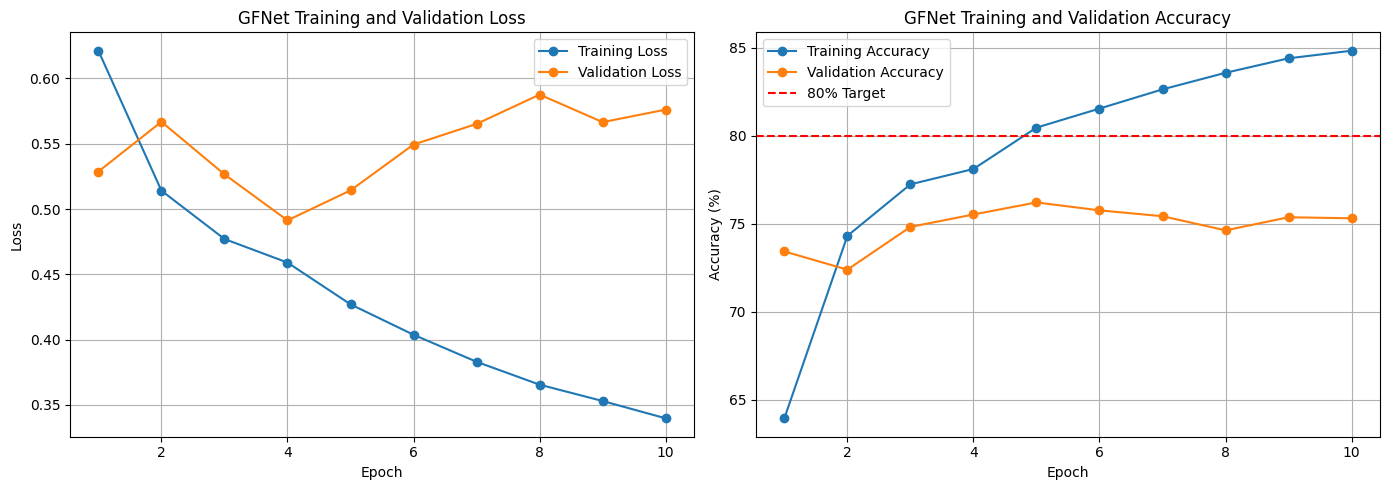

In [47]:
# Create epoch numbers
epoch_numbers = []

for i in range(epochs):
    epoch_numbers.append(i + 1)

# Create plots
plt.figure(figsize=(14, 5))

# ========================================
# 1. Loss curves
# ========================================

plt.subplot(1, 2, 1)

plt.plot(
    epoch_numbers,
    train_loss_history,
    label="Training Loss",
    marker="o"
)

plt.plot(
    epoch_numbers,
    val_loss_history,
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GFNet Training and Validation Loss")
plt.legend()
plt.grid(True)

# ========================================
# 2. Accuracy curves
# ========================================

plt.subplot(1, 2, 2)

plt.plot(
    epoch_numbers,
    np.array(train_acc_history) * 100,
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    epoch_numbers,
    np.array(val_acc_history) * 100,
    label="Validation Accuracy",
    marker="o"
)

# Show the 80% target
plt.axhline(
    y=80,
    color="red",
    linestyle="--",
    label="80% Target"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("GFNet Training and Validation Accuracy")
plt.legend()
plt.grid(True)

# Display plots
plt.tight_layout()
plt.show()

# Step 6.4: Evaluate Final Model on Validation Set

Evaluate the final trained GFNet model on the validation dataset to measure generalization performance without updating model parameters.

In [76]:
# Load the best model selected by validation loss
# checkpoint_path = (
#     "/content/drive/MyDrive/COMP3710/project/gfnet_best.pth"
# )
# checkpoint_path = (
#     "/content/drive/MyDrive/COMP3710/project/"
#     "gfnet_v6_dropout03_best.pth"
# )

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print("Loaded best checkpoint:", checkpoint_path)

# Initialize validation metrics
total_loss = 0.0
correct = 0
total = 0

# Disable gradient computation
with torch.no_grad():

    for images, labels in val_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Accumulate loss
        total_loss += loss.item() * images.size(0)

        # Get predictions
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

# Calculate validation metrics
validation_loss = total_loss / total
validation_acc = correct / total

# Display results
print("GFNet Validation Results")
print("-------------------------")
print("Validation images:", total)
print(f"Validation Loss: {validation_loss:.4f}")
print(f"Validation Accuracy: {validation_acc * 100:.2f}%")

Loaded best checkpoint: /content/drive/MyDrive/COMP3710/project/gfnet_best.pth
GFNet Validation Results
-------------------------
Validation images: 4460
Validation Loss: 0.5716
Validation Accuracy: 73.09%


## Step 7: Evaluate GFNet Model

Evaluate the trained GFNet model on the patient-independent test dataset. Measure classification accuracy and test loss to assess generalization performance.

### Step 7.1: Calculate Test Loss and Accuracy

In [77]:
# Set model to evaluation mode
model.eval()

# Initialize evaluation variables
total_loss = 0.0
correct = 0
total = 0

# Disable gradient calculation
with torch.no_grad():

    for images, labels in test_loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Accumulate loss
        total_loss += loss.item() * images.size(0)

        # Get predicted classes
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

# Calculate average test loss and accuracy
test_loss = total_loss / total
test_acc = correct / total

# Display results
print("GFNet Test Results")
print("-------------------------")
print("Test images:", total)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Check project accuracy requirement
if test_acc >= 0.80:
    print("PASS: GFNet meets the 80% accuracy requirement.")
else:
    print("BELOW TARGET: GFNet test accuracy is below 80%.")

GFNet Test Results
-------------------------
Test images: 4440
Test Loss: 0.5983
Test Accuracy: 73.29%
BELOW TARGET: GFNet test accuracy is below 80%.


### Step 7.2: Inspect GFNet Prediction Distribution

Inspect the predicted class distribution on the test dataset to identify potential class prediction bias.

In [27]:
# Set model to evaluation mode
model.eval()

# Store predictions and actual labels
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Get predicted classes
        predictions = torch.argmax(outputs, dim=1)

        # Store results
        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

# Count predictions for each class
predicted_nc = all_predictions.count(0)
predicted_ad = all_predictions.count(1)

# Count actual labels for each class
actual_nc = all_labels.count(0)
actual_ad = all_labels.count(1)

print("GFNet Prediction Distribution")
print("----------------------------")
print("Predicted NC:", predicted_nc)
print("Predicted AD:", predicted_ad)

print("\nActual Test Distribution")
print("----------------------------")
print("Actual NC:", actual_nc)
print("Actual AD:", actual_ad)

GFNet Prediction Distribution
----------------------------
Predicted NC: 2206
Predicted AD: 1234

Actual Test Distribution
----------------------------
Actual NC: 1060
Actual AD: 2380


### Step 7.3: Confusion Matrix

Generate a confusion matrix to examine GFNet classification errors and identify differences in performance between NC and AD.

Confusion Matrix:
[[ 839  221]
 [1367 1013]]


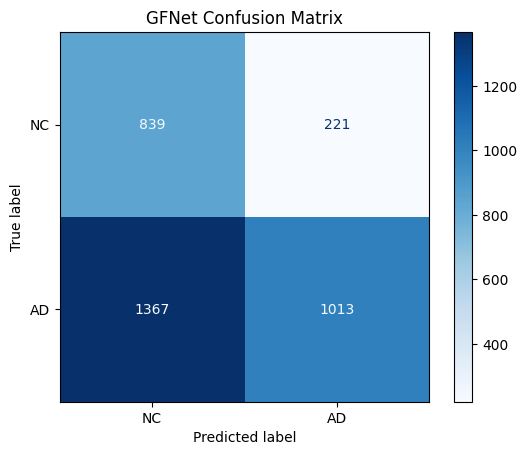

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NC", "AD"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("GFNet Confusion Matrix")
plt.show()

### Step 7.4: Classification Report

Calculate precision, recall, and F1-score for each class. Report macro-averaged metrics to evaluate GFNet classification performance.

In [29]:
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate classification report
report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["NC", "AD"],
    digits=4,
    zero_division=0
)

print("GFNet Classification Report")
print("---------------------------")
print(report)

# Calculate macro-averaged metrics
macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("Macro Precision:", round(macro_precision, 4))
print("Macro Recall:", round(macro_recall, 4))
print("Macro F1-score:", round(macro_f1, 4))

GFNet Classification Report
---------------------------
              precision    recall  f1-score   support

          NC     0.3803    0.7915    0.5138      1060
          AD     0.8209    0.4256    0.5606      2380

    accuracy                         0.5384      3440
   macro avg     0.6006    0.6086    0.5372      3440
weighted avg     0.6851    0.5384    0.5462      3440

Macro Precision: 0.6006
Macro Recall: 0.6086
Macro F1-score: 0.5372


### Step 7.5: Calculate AUROC

Evaluate GFNet using the Area Under the Receiver Operating Characteristic Curve (AUROC). Use predicted probabilities for the AD class to measure classification performance across different decision thresholds.

In [30]:
from sklearn.metrics import roc_auc_score, roc_curve

# Store actual labels and predicted probabilities
roc_labels = []
roc_probs = []

# Set model to evaluation mode
model.eval()

# Disable gradient computation
with torch.no_grad():

    for images, labels in test_loader:

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Convert outputs to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get probabilities for AD (class 1)
        ad_probs = probabilities[:, 1]

        # Store results
        roc_labels.extend(labels.tolist())
        roc_probs.extend(ad_probs.cpu().tolist())

# Calculate AUROC
auroc = roc_auc_score(roc_labels, roc_probs)

print("GFNet AUROC:", round(auroc, 4))

GFNet AUROC: 0.6668


### Step 7.6: Plot ROC Curve

Plot the Receiver Operating Characteristic (ROC) curve to visualize GFNet's ability to distinguish Alzheimer's Disease (AD) from Normal Control (NC) across different classification thresholds.

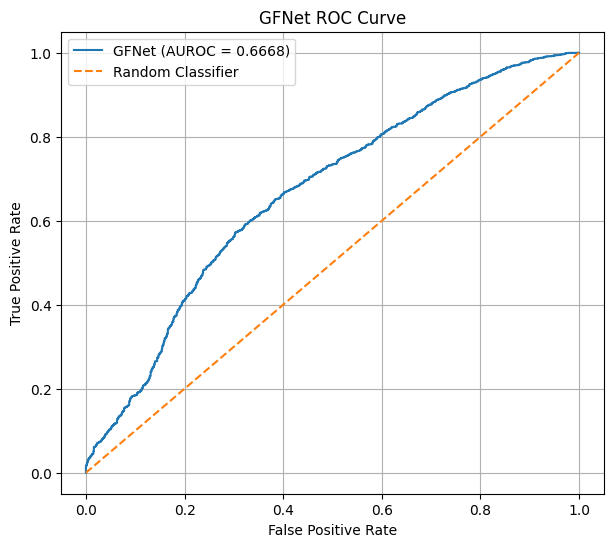

In [31]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(roc_labels, roc_probs)

# Create figure
plt.figure(figsize=(7, 6))

# Plot ROC curve
plt.plot(
    fpr,
    tpr,
    label=f"GFNet (AUROC = {auroc:.4f})"
)

# Plot random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

# Add labels and title
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GFNet ROC Curve")

# Add legend and grid
plt.legend()
plt.grid(True)

# Display plot
plt.show()

### Step 8.1: Analyse GFNet Training Performance

Visualize training loss and accuracy across 30 epochs to investigate model convergence and potential overfitting.

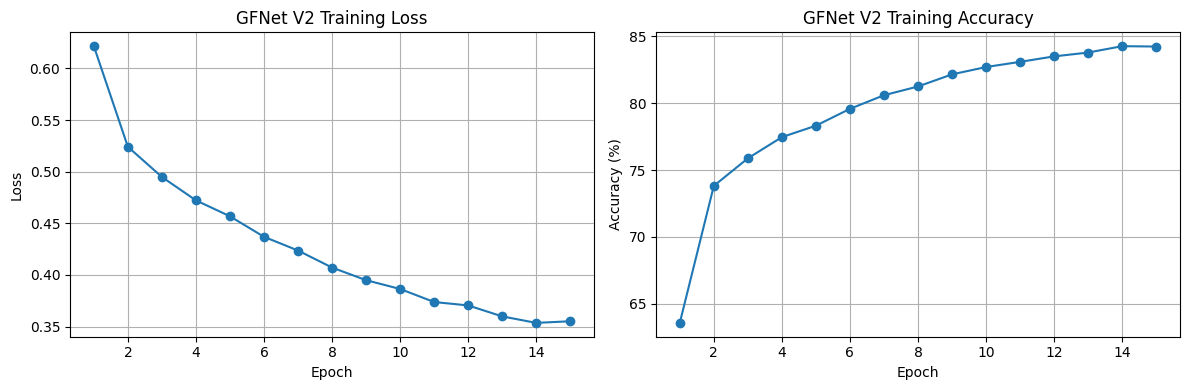

In [32]:
# Create epoch numbers
epoch_numbers = []

for i in range(len(train_loss_history)):
    epoch_numbers.append(i + 1)

# Convert accuracy to percentage
train_acc_percent = []

for acc in train_acc_history:
    train_acc_percent.append(acc * 100)

# Create figure
plt.figure(figsize=(12, 4))

# Plot training loss
plt.subplot(1, 2, 1)

plt.plot(
    epoch_numbers,
    train_loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GFNet V2 Training Loss")
plt.grid(True)

# Plot training accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epoch_numbers,
    train_acc_percent,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("GFNet V2 Training Accuracy")
plt.grid(True)

# Display plots
plt.tight_layout()
plt.show()